Note: you may need to restart the kernel to use updated packages.
DATASET LOADED
Rows: 2
Columns: 13


,Company,Ticker,Exchange,Country / HQ,Shares outstanding,Share price (NOK),Market capitalisation (NOK),Trailing P/E,EPS (NOK),50-day MA (NOK),200-day MA (NOK),2024 revenue (NOK million),Notes
0,P/F Bakkafrost,BAKKA,Oslo Børs,Faroe Islands,59389741.0,430.6,25532166487,22.29,9.95,454.71,451.48,NaN,Faroese salmon farming and value-chain company...
1,Grieg Seafood ASA,GSF,Oslo Stock Exchange,"Bergen, Norway",NaN,NaN,2580000000,NaN,NaN,NaN,NaN,7381.0,Atlantic salmon farmer; operations in Rogaland...



COLUMN NAMES:
['company', 'ticker', 'exchange', 'country_hq', 'shares_outstanding', 'share_price_nok', 'market_capitalisation_nok', 'trailing_p_e', 'eps_nok', '50_day_ma_nok', '200_day_ma_nok', '2024_revenue_nok_million', 'notes']

DATA TYPES:
company                          str
ticker                           str
exchange                         str
country_hq                       str
shares_outstanding           float64
share_price_nok              float64
market_capitalisation_nok      int64
trailing_p_e                 float64
eps_nok                      float64
50_day_ma_nok                float64
200_day_ma_nok               float64
2024_revenue_nok_million     float64
notes                            str
dtype: object

MISSING VALUES:


,Missing Values
company,0
ticker,0
exchange,0
country_hq,0
shares_outstanding,1
share_price_nok,1
market_capitalisation_nok,0
trailing_p_e,1
eps_nok,1
50_day_ma_nok,1



DUPLICATES: 0

STATISTICAL SUMMARY:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
company,2,2,P/F Bakkafrost,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ticker,2,2,BAKKA,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
exchange,2,2,Oslo Børs,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_hq,2,2,Faroe Islands,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shares_outstanding,1.0,NaN,NaN,NaN,59389741.0,NaN,59389741.0,59389741.0,59389741.0,59389741.0,59389741.0
share_price_nok,1.0,NaN,NaN,NaN,430.6,NaN,430.6,430.6,430.6,430.6,430.6
market_capitalisation_nok,2.0,NaN,NaN,NaN,14056083243.5,16229632565.880318,2580000000.0,8318041621.75,14056083243.5,19794124865.25,25532166487.0
trailing_p_e,1.0,NaN,NaN,NaN,22.29,NaN,22.29,22.29,22.29,22.29,22.29
eps_nok,1.0,NaN,NaN,NaN,9.95,NaN,9.95,9.95,9.95,9.95,9.95
50_day_ma_nok,1.0,NaN,NaN,NaN,454.71,NaN,454.71,454.71,454.71,454.71,454.71



DATE COLUMNS: []

CLEANED DATA:


,company,ticker,exchange,country_hq,shares_outstanding,share_price_nok,market_capitalisation_nok,trailing_p_e,eps_nok,50_day_ma_nok,200_day_ma_nok,2024_revenue_nok_million,notes
0,P/F Bakkafrost,BAKKA,Oslo Børs,Faroe Islands,59389741.0,430.6,25532166487,22.29,9.95,454.71,451.48,NaN,Faroese salmon farming and value-chain company...
1,Grieg Seafood ASA,GSF,Oslo Stock Exchange,"Bergen, Norway",NaN,NaN,2580000000,NaN,NaN,NaN,NaN,7381.0,Atlantic salmon farmer; operations in Rogaland...



NUMERIC COLUMNS: ['shares_outstanding', 'share_price_nok', 'market_capitalisation_nok', 'trailing_p_e', 'eps_nok', '50_day_ma_nok', '200_day_ma_nok', '2024_revenue_nok_million']
IDENTIFIER COLUMNS: ['company', 'ticker']
TEXT COLUMNS: ['exchange', 'country_hq', 'notes']


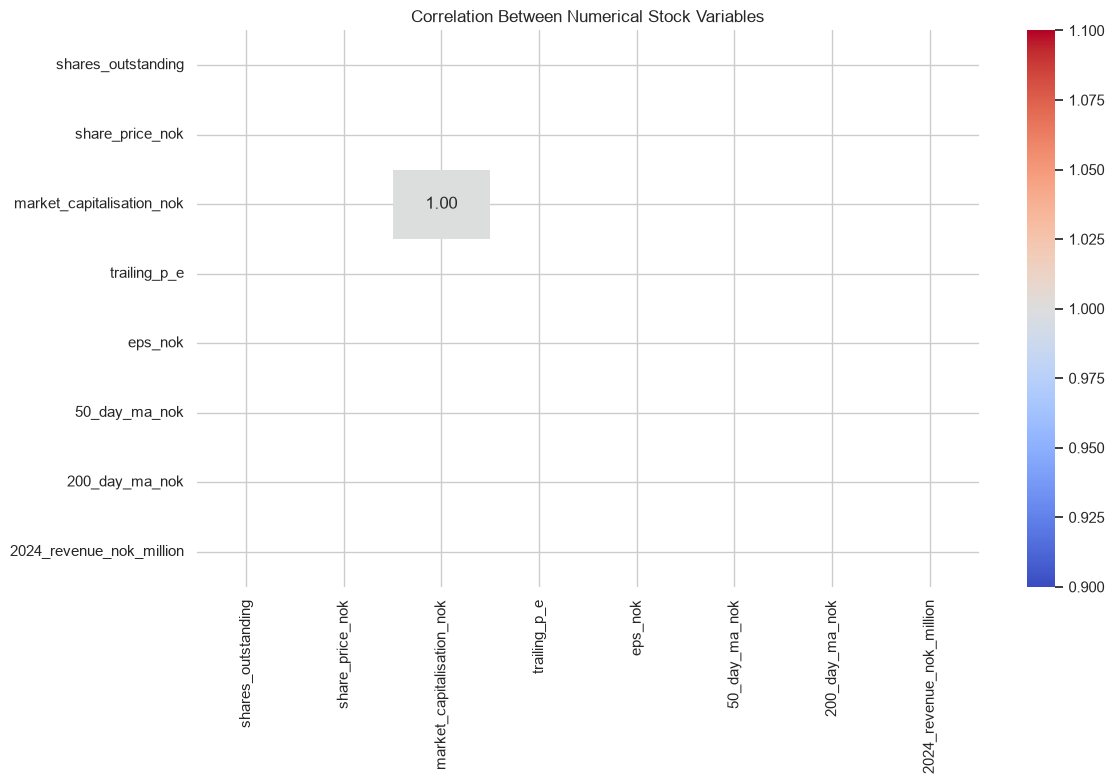

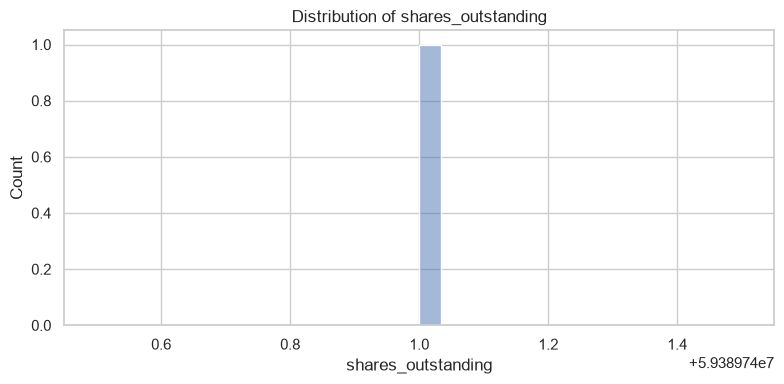

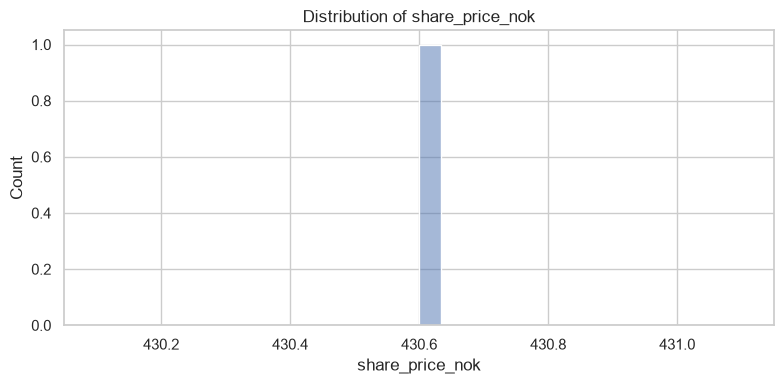

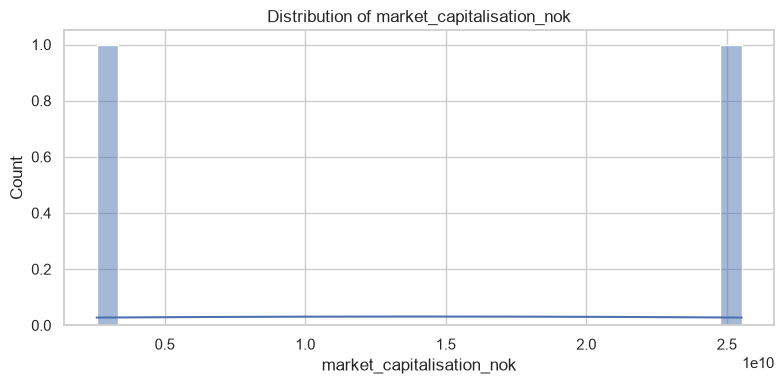

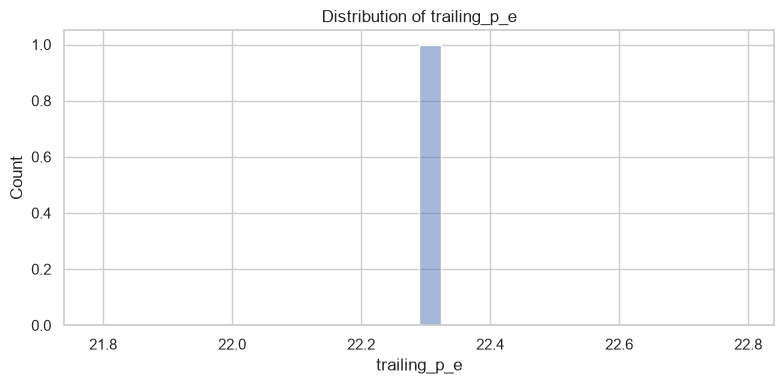

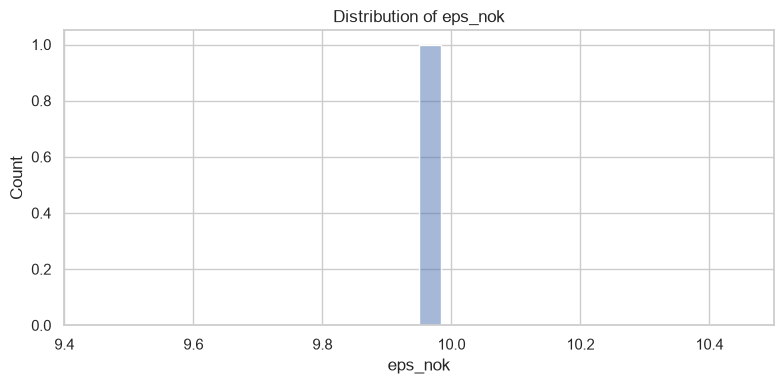

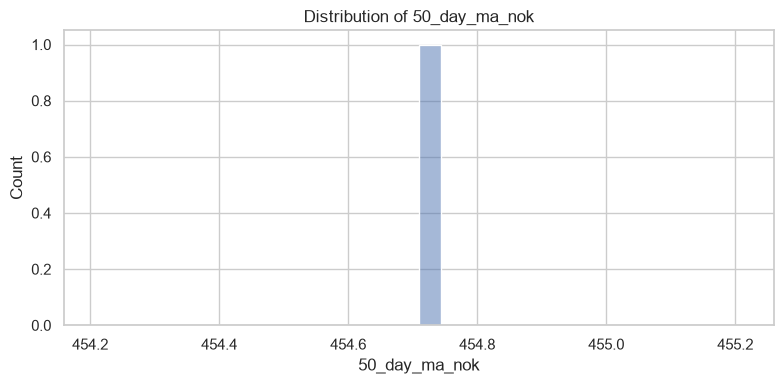

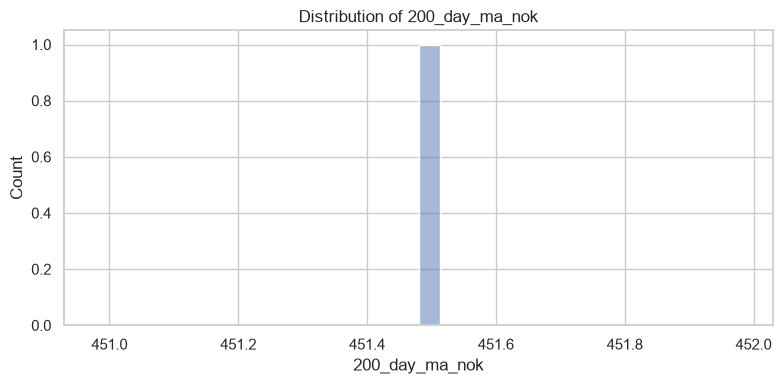

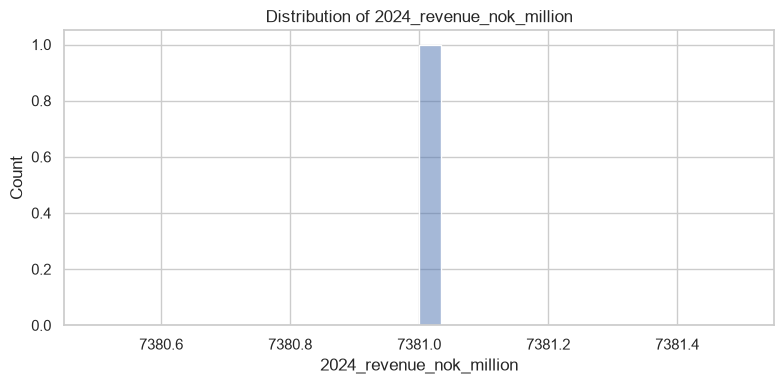

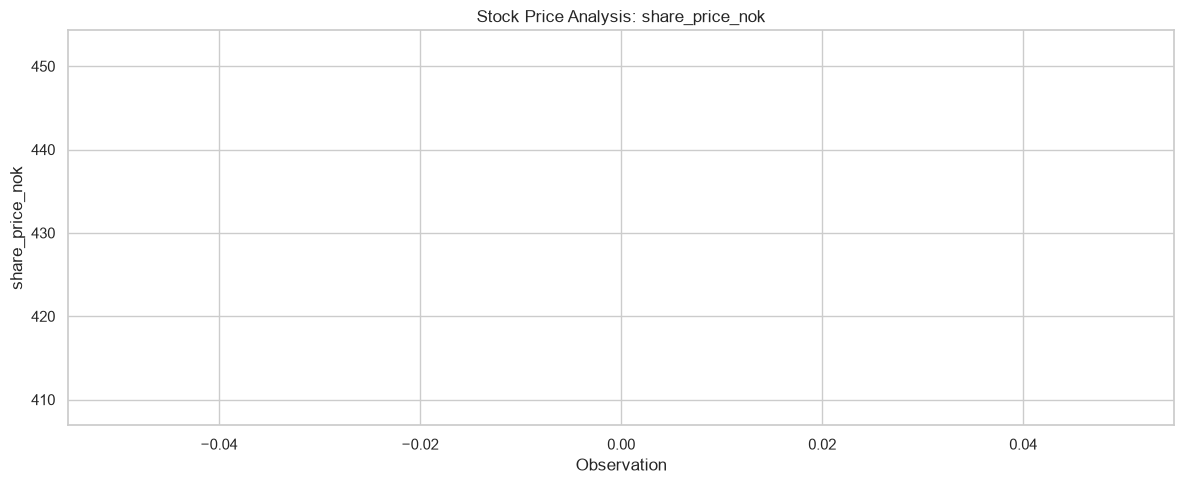


K-MEANS FEATURES:
['market_capitalisation_nok']


ValueError: At least three observations are required.

In [1]:

# ================================================================
# BAKKAFROST & GRIEG SEAFOOD STOCK SHARES
# FULL DATA ANALYSIS: K-MEANS CLUSTERING + NLP
# ================================================================

# STEP 1: INSTALL LIBRARIES
%pip install -q pandas numpy matplotlib seaborn scikit-learn nltk

# STEP 2: IMPORT LIBRARIES
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# STEP 3: LOAD DATASET
FILE_PATH = "Bakkafrost_Grieg_Seafood_Stock_Shares.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"Cannot find {FILE_PATH}. "
        "Place the CSV in the notebook folder or update FILE_PATH."
    )

df = pd.read_csv(FILE_PATH)

print("=" * 70)
print("DATASET LOADED")
print("=" * 70)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

# STEP 4: STANDARDISE COLUMN NAMES
df.columns = [
    re.sub(r"[^a-zA-Z0-9]+", "_", str(c).strip()).strip("_").lower()
    for c in df.columns
]

# STEP 5: INITIAL DATA EXPLORATION
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
display(df.isna().sum().to_frame("Missing Values"))

print("\nDUPLICATES:", df.duplicated().sum())

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T)

# STEP 6: REMOVE DUPLICATES AND EMPTY ROWS
df = df.drop_duplicates().dropna(how="all").copy()

# STEP 7: DETECT AND PARSE DATE COLUMNS
date_candidates = [
    c for c in df.columns
    if "date" in c or "timestamp" in c
    or c in ["datetime", "time"]
]

date_cols = []

for col in date_candidates:
    parsed = pd.to_datetime(df[col], errors="coerce", dayfirst=True)

    if parsed.notna().mean() >= 0.5:
        df[col] = parsed
        date_cols.append(col)

print("\nDATE COLUMNS:", date_cols)

# STEP 8: CONVERT NUMERIC-LIKE TEXT TO NUMBERS
for col in df.select_dtypes(include=["object", "string"]).columns:
    if col in date_cols:
        continue

    values = df[col].astype(str).str.strip()
    values = values.str.replace(",", "", regex=False)
    values = values.str.replace(r"[$£€%]", "", regex=True)

    converted = pd.to_numeric(values, errors="coerce")
    valid_count = df[col].notna().sum()

    if valid_count > 0:
        ratio = converted.notna().sum() / valid_count
        if ratio >= 0.85:
            df[col] = converted

print("\nCLEANED DATA:")
display(df.head())

# STEP 9: IDENTIFY NUMERIC, TEXT AND COMPANY COLUMNS
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

identifier_cols = [
    c for c in df.columns
    if any(x in c for x in [
        "ticker", "symbol", "company", "stock_name", "issuer"
    ])
]

text_cols = [
    c for c in df.select_dtypes(include=["object", "string"]).columns
    if c not in identifier_cols
]

print("\nNUMERIC COLUMNS:", numeric_cols)
print("IDENTIFIER COLUMNS:", identifier_cols)
print("TEXT COLUMNS:", text_cols)

# STEP 10: EXPLORATORY DATA ANALYSIS
if len(numeric_cols) >= 2:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Between Numerical Stock Variables")
    plt.tight_layout()
    plt.show()

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

# STEP 11: STOCK PRICE VISUALISATION
price_cols = [
    c for c in df.columns
    if any(x in c for x in [
        "close", "adj_close", "adjusted_close",
        "share_price", "stock_price", "price"
    ])
    and pd.api.types.is_numeric_dtype(df[c])
]

date_col = next(
    (c for c in date_cols
     if pd.api.types.is_datetime64_any_dtype(df[c])),
    None
)

if price_cols:
    for col in price_cols:
        plt.figure(figsize=(12, 5))

        if date_col:
            temp = df[[date_col, col]].dropna().sort_values(date_col)
            plt.plot(temp[date_col], temp[col])
            plt.xlabel("Date")
            plt.xticks(rotation=45)
        else:
            plt.plot(df[col].reset_index(drop=True))
            plt.xlabel("Observation")

        plt.ylabel(col)
        plt.title(f"Stock Price Analysis: {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No recognised numeric price column detected.")

# STEP 12: PREPARE K-MEANS FEATURES
work = df.copy()

company_col = next(
    (c for c in identifier_cols if c in work.columns),
    None
)

close_col = next(
    (c for c in price_cols if "close" in c),
    price_cols[0] if price_cols else None
)

if date_col and close_col:
    sort_cols = [date_col]
    if company_col:
        sort_cols = [company_col, date_col]

    work = work.sort_values(sort_cols).copy()

    if company_col:
        work["daily_return_pct"] = (
            work.groupby(company_col)[close_col].pct_change() * 100
        )
        work["rolling_volatility_20"] = (
            work.groupby(company_col)["daily_return_pct"]
            .transform(lambda s: s.rolling(20, min_periods=5).std())
        )
    else:
        work["daily_return_pct"] = work[close_col].pct_change() * 100
        work["rolling_volatility_20"] = (
            work["daily_return_pct"].rolling(20, min_periods=5).std()
        )

excluded_words = ["id", "unnamed"]

cluster_features = [
    c for c in work.select_dtypes(include=np.number).columns
    if not any(word in c for word in excluded_words)
    and work[c].nunique(dropna=True) > 1
]

if not cluster_features:
    raise ValueError(
        "No suitable numeric features found for K-Means. "
        "Check the dataset's columns and data types."
    )

print("\nK-MEANS FEATURES:")
print(cluster_features)

# STEP 13: IMPUTE MISSING VALUES AND SCALE FEATURES
X_raw = work[cluster_features].replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

if len(X_scaled) < 3:
    raise ValueError("At least three observations are required.")

print("Feature matrix shape:", X_scaled.shape)

# STEP 14: FIND BEST K USING SILHOUETTE SCORE
max_k = min(10, len(X_scaled) - 1)
scores = {}

for k in range(2, max_k + 1):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    if len(np.unique(labels)) > 1:
        scores[k] = silhouette_score(X_scaled, labels)

if not scores:
    raise ValueError("Could not calculate silhouette scores.")

best_k = max(scores, key=scores.get)

print("\nSILHOUETTE SCORES:")
print(scores)
print("SELECTED K:", best_k)

plt.figure(figsize=(8, 5))
plt.plot(list(scores.keys()), list(scores.values()), marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Choosing K for K-Means")
plt.xticks(list(scores.keys()))
plt.tight_layout()
plt.show()

# STEP 15: TRAIN K-MEANS
kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

work["cluster"] = kmeans.fit_predict(X_scaled)

print("\nCLUSTER COUNTS:")
display(work["cluster"].value_counts().sort_index().to_frame("Count"))

# STEP 16: PROFILE EACH CLUSTER
cluster_profile = (
    work.groupby("cluster")[cluster_features]
    .mean()
    .round(3)
)

print("\nCLUSTER FEATURE PROFILES:")
display(cluster_profile)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=work,
    x="cluster",
    hue="cluster",
    palette="Set2",
    legend=False
)
plt.title("Stock Observations per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

# STEP 17: VISUALISE CLUSTERS USING PCA
if X_scaled.shape[1] >= 2:
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X_scaled)

    pca_df = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "Cluster": work["cluster"].to_numpy()
    })

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="Set1",
        s=65
    )
    plt.title("K-Means Stock Clusters (PCA Projection)")
    plt.tight_layout()
    plt.show()

    print("PCA explained variance:", pca.explained_variance_ratio_)
else:
    print("PCA plot requires at least two numeric features.")

# ================================================================
# NLP ANALYSIS
# ================================================================

# STEP 18: DOWNLOAD NLP RESOURCES
nltk.download("stopwords", quiet=True)
nltk.download("vader_lexicon", quiet=True)

try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    stop_words = set()

# STEP 19: PREPARE NLP TEXT
# If the CSV contains text columns, analyse those columns.
# Otherwise, use example text strictly to demonstrate the pipeline.

if text_cols:
    nlp_df = work.copy()

    nlp_df["nlp_text"] = (
        nlp_df[text_cols]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
        .str.strip()
    )

    nlp_df = nlp_df[nlp_df["nlp_text"].str.len() > 0].copy()

    print("Using text columns from CSV:", text_cols)

else:
    print(
        "No text columns detected. Using illustrative example sentences, "
        "not actual Bakkafrost or Grieg Seafood news."
    )

    nlp_df = pd.DataFrame({
        "nlp_text": [
            "The company reported stronger revenue and improved earnings.",
            "Seafood demand weakened and operating costs increased.",
            "The share price remained stable during trading.",
            "Analysts reported positive growth opportunities.",
            "Higher feed costs may reduce profit margins.",
            "The company announced an investment in sustainable production.",
            "Trading was volatile and the stock closed lower.",
            "The quarterly report showed revenue growth and improved cash flow."
        ]
    })

# STEP 20: CLEAN TEXT
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = [
        word for word in text.split()
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)

nlp_df["clean_text"] = nlp_df["nlp_text"].apply(clean_text)

nlp_df = nlp_df[nlp_df["clean_text"].str.strip().ne("")].copy()

display(nlp_df[["nlp_text", "clean_text"]].head(10))

# STEP 21: TF-IDF VECTORIZATION
X_text = None
tfidf = None

if len(nlp_df) >= 2:
    tfidf = TfidfVectorizer(
        max_features=1000,
        ngram_range=(1, 2),
        min_df=1
    )

    X_text = tfidf.fit_transform(nlp_df["clean_text"])

    print("TF-IDF matrix shape:", X_text.shape)

    terms = tfidf.get_feature_names_out()
    weights = np.asarray(X_text.mean(axis=0)).ravel()
    top_indices = weights.argsort()[::-1][:20]

    top_terms = pd.DataFrame({
        "Term": terms[top_indices],
        "Mean_TFIDF": weights[top_indices]
    })

    display(top_terms)

    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=top_terms.sort_values("Mean_TFIDF"),
        x="Mean_TFIDF",
        y="Term"
    )
    plt.title("Top 20 TF-IDF Terms")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough text documents for TF-IDF.")

# STEP 22: SENTIMENT ANALYSIS WITH VADER
try:
    sia = SentimentIntensityAnalyzer()

    sentiment_results = nlp_df["nlp_text"].apply(
        lambda text: sia.polarity_scores(str(text))
    )

    sentiment_df = pd.DataFrame(
        sentiment_results.tolist(),
        index=nlp_df.index
    )

    nlp_df = nlp_df.join(sentiment_df)

    nlp_df["sentiment"] = np.select(
        [
            nlp_df["compound"] >= 0.05,
            nlp_df["compound"] <= -0.05
        ],
        ["Positive", "Negative"],
        default="Neutral"
    )

    display(
        nlp_df[
            ["nlp_text", "neg", "neu", "pos", "compound", "sentiment"]
        ].head(20)
    )

    plt.figure(figsize=(8, 5))
    sns.countplot(
        data=nlp_df,
        x="sentiment",
        order=["Negative", "Neutral", "Positive"],
        hue="sentiment",
        palette="Set2",
        legend=False
    )
    plt.title("NLP Sentiment Analysis")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Texts")
    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Sentiment analysis error:", e)

# STEP 23: K-MEANS CLUSTERING OF TEXT DOCUMENTS
# This is separate from stock-price clustering.

if X_text is not None and X_text.shape[0] >= 3:
    text_scores = {}
    max_text_k = min(6, X_text.shape[0] - 1)

    for k in range(2, max_text_k + 1):
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )

        labels = model.fit_predict(X_text)

        if len(np.unique(labels)) > 1:
            text_scores[k] = silhouette_score(
                X_text, labels, metric="cosine"
            )

    text_best_k = (
        max(text_scores, key=text_scores.get)
        if text_scores else 2
    )

    text_kmeans = KMeans(
        n_clusters=text_best_k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    nlp_df["text_cluster"] = text_kmeans.fit_predict(X_text)

    print("Text silhouette scores:", text_scores)
    print("Selected text cluster count:", text_best_k)

    display(nlp_df[["nlp_text", "text_cluster"]])

    vocabulary = tfidf.get_feature_names_out()

    for cluster_id in sorted(nlp_df["text_cluster"].unique()):
        positions = np.flatnonzero(
            nlp_df["text_cluster"].to_numpy() == cluster_id
        )

        average_weights = np.asarray(
            X_text[positions].mean(axis=0)
        ).ravel()

        top_ids = average_weights.argsort()[::-1][:10]

        print(
            f"Text cluster {cluster_id} representative terms:",
            ", ".join(vocabulary[top_ids])
        )
else:
    print("Not enough text documents for text clustering.")

# STEP 24: EXPORT ALL RESULTS
work.to_csv("bakkafrost_grieg_kmeans_results.csv", index=False)
nlp_df.to_csv("bakkafrost_grieg_nlp_results.csv", index=False)

cluster_profile.to_csv("bakkafrost_grieg_cluster_profiles.csv")

print("\nFiles saved:")
print("1. bakkafrost_grieg_kmeans_results.csv")
print("2. bakkafrost_grieg_nlp_results.csv")
print("3. bakkafrost_grieg_cluster_profiles.csv")

# STEP 25: FINAL SUMMARY
print("\n" + "=" * 70)
print("FINAL ANALYSIS SUMMARY")
print("=" * 70)

print("Number of stock observations:", len(work))
print("Number of numerical features:", len(cluster_features))
print("Selected K-Means clusters:", best_k)
print("Stock cluster sizes:")
print(work["cluster"].value_counts().sort_index())

print("\nNumber of NLP documents:", len(nlp_df))

if "sentiment" in nlp_df.columns:
    print("\nSentiment distribution:")
    print(nlp_df["sentiment"].value_counts())

if "text_cluster" in nlp_df.columns:
    print("\nText cluster sizes:")
    print(nlp_df["text_cluster"].value_counts().sort_index())

print("\nANALYSIS COMPLETED SUCCESSFULLY.")
print(
    "Note: Clusters and sentiment scores are exploratory, "
    "not financial advice or stock-price predictions."
)
